# Introducción y objetivo

## **Información General**
### **Datasets**
* **Siniestros viales**: https://data.buenosaires.gob.ar/ar/dataset/victimas-siniestros-viales/resource/40ec993a-00ad-40e5-936f-0a25f8d2c90b
* **Comunas de CABA**: https://data.buenosaires.gob.ar/el/dataset/comunas


## **Formulación del Problema**
El objetivo de este proyecto es desarrollar un modelo de regresión que permita predecir la cantidad de siniestros viales esperados en la Ciudad de Buenos Aires según factores temporales y geográficos.
La predicción busca identificar combinaciones de zonas y momentos con mayor riesgo de ocurrencia de siniestros. Los patrones identificados podrán utilizarse como información para la planificación de controles y recursos de seguridad vial.
La variable objetivo será la **Cantidad de siniestros registrados** para cada combinación de fecha, comuna y franja horaria.

**Métrica de éxito**: como el objetivo de este análisis es priorizar dónde y cuándo implementar controles y recursos de seguridad vial, la métrica principal que usaré es el **Lift@5%**, que mide cuántas veces más siniestros tienen, en promedio, el 5% de las combinaciones que el modelo señala como de mayor riesgo con respecto al promedio general.
Como métricas complementarias usaré el MAE y el MSE, para evaluar el error en la cantidad estimada de siniestros.
En todos los casos los modelos se comparan contra un baseline.

## **Preguntas de Análisis**

* ¿Cómo se distribuyen los siniestros viales en CABA según la ubicación y el momento en que ocurren?
* ¿Qué patrones permiten identificar zonas y horarios de mayor ocurrencia?

Los patrones identificados podrán utilizarse como información para orientar la priorización de medidas preventivas y recursos de seguridad vial.

# Carga y exploración inicial

## **Carga de librerías**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
import shap

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## Declaración de Funciones

In [2]:
def calcular_lift(y_test, predict_model, porcentaje):

    """ Calcula el lift@ definido en la variable porcentaje"""

    # Si todas las predicciones son iguales, no se pueden ordenar las combinaciones y el lift no tiene sentido.
    if np.std(predict_model) == 0:
        return np.nan

    top_x = int(len(predict_model) * porcentaje)
    if top_x <= 0:
        return np.nan

    indices_top_x = np.argsort(predict_model)[-top_x:]
    indices_top_x_desc = indices_top_x[::-1]

    promedio_valores_y_test_top_x = y_test.iloc[indices_top_x_desc].mean()
    promedio_y_test = y_test.mean()

    lift_x = promedio_valores_y_test_top_x / promedio_y_test
    return lift_x

def baseline_historico(X_tr, y_tr, X_val, columnas):
    """ Predice para X_val el promedio histórico de siniestros por las columnas indicadas. Calculado con X_tr e Y_tr. """
    datos_train = X_tr.assign(y=y_tr.values)
    promedios = datos_train.groupby(columnas, observed=True)["y"].mean().reset_index()
    return X_val.merge(promedios, on=columnas, how="left")["y"].values

def evaluar_cv(pipeline, X, y, cv_splits):
    """ Entrena el pipeline en cada fold y devuelve las listas de MAE, MSE y Lift@5% de cada fold. """
    MAE_folds = []
    MSE_folds = []
    lift5_folds = []

    for train_index, val_index in cv_splits:
        X_train_fold = X.iloc[train_index]
        X_val_fold = X.iloc[val_index]

        y_train_fold = y.iloc[train_index]
        y_val_fold = y.iloc[val_index]

        modelo = clone(pipeline)
        modelo.fit(X_train_fold, y_train_fold)
        predict_fold = modelo.predict(X_val_fold)

        #MAE
        MAE_folds.append(mean_absolute_error(y_val_fold, predict_fold))
        #MSE
        MSE_folds.append(mean_squared_error(y_val_fold, predict_fold))
        # Lift@5%
        lift5_folds.append(calcular_lift(y_val_fold, predict_fold, 0.05))

    return MAE_folds, MSE_folds, lift5_folds

print("Funciones declaradas: calcular_lift, baseline_historico y evaluar_cv")


Funciones declaradas: calcular_lift, baseline_historico y evaluar_cv


## Declaración de Constantes

In [3]:
# URL Datasets
DATASETS_PATH = "https://raw.githubusercontent.com/maguita/DS2-Trabajo-Final/refs/heads/main/data"
# EPSG:4326, habitual para coordenadas expresadas en longitud y latitud.
CRS_COORDENADAS = "EPSG:4326"
COLUMNAS_BASELINE = ["comuna_siniestro", "franja_horaria", "dia_semana"]

print(f"Datasets: {DATASETS_PATH}")

Datasets: https://raw.githubusercontent.com/maguita/DS2-Trabajo-Final/refs/heads/main/data


## Carga de datos

In [4]:
# Siniestros
df_siniestros = pd.read_csv(f"{DATASETS_PATH}/siniestros_viales_hechos.csv", sep=";")
df_siniestros_copy = df_siniestros.copy()

# Comunas
gdf_comunas = gpd.read_file(f"{DATASETS_PATH}/comunas.geojson")

/tmp/ipykernel_4420/2439393789.py:2: DtypeWarning: Columns (1,10,15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_siniestros = pd.read_csv(f"{DATASETS_PATH}/siniestros_viales_hechos.csv", sep=";")


In [5]:
# Verifico que no haya siniestros duplicados
print(f"Filas: {len(df_siniestros_copy)}, ids distintos: {df_siniestros_copy['id_siniestro'].nunique()}")

Filas: 65818, ids distintos: 65818


Cada registro corresponde a un siniestro único.

In [6]:
# Estructura Siniestros
print(f"Shape: {df_siniestros_copy.shape}")

# Exploro las primeras filas
display(df_siniestros_copy.head())

Shape: (65818, 21)


,id_siniestro,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,hora_siniestro,...,direccion_normalizada_siniestro,comuna_siniestro,tipo_de_via_siniestro,geocodificacion_plana,longitud_siniestro,latitud_siniestro,participantes_siniestro,modo_desplazamiento_victima,contraparte_siniestro,gravedad_siniestro
0,LC-2019-0000053,1,1,0,0,2019-01-01,2019,1,1,01:55:00,...,NaN,Comuna 8,AUTOPISTA,POINT (101813.84712503915943671 95578.55507230...,-58.44351,-34.669125,AUTO-UTILITARIO,AUTO,UTILITARIO,LEVE
1,LC-2019-0000647,1,0,1,0,2019-01-01,2019,1,1,18:50:00,...,DE LOS CONSTITUYENTES AV. y HABANA,Comuna 12,AVENIDA,POINT (97510.27137648081406951 105087.83369881...,-58.490436,-34.583403,MOTO-AUTO,MOTO,AUTO,GRAVE
2,LC-2019-0000445,3,3,0,0,2019-01-01,2019,1,1,13:40:00,...,NaN,Comuna 11,NaN,POINT (94371.44237885093025398 102884.19365105...,-58.524662,-34.603255,AUTO-AUTO,AUTO,AUTO,LEVE
3,LC-2019-0000194,1,1,0,0,2019-01-01,2019,1,1,07:15:00,...,NaN,Comuna 9,NaN,POINT (94030.76669932194636203 97681.071761248...,-58.528413,-34.650156,AUTO-CAMION,AUTO,CAMION,LEVE
4,LC-2019-0000329,1,1,0,0,2019-01-01,2019,1,1,12:24:00,...,NaN,Comuna 4,NaN,POINT (105367.86665769023238681 97877.75085908...,-58.404748,-34.648387,AUTO-MOVIL,AUTO,MOVIL,LEVE


### Resumen estadístico

In [7]:
df_siniestros_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65818 entries, 0 to 65817
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   id_siniestro                      65818 non-null  object
 1   numero_total_de_victimas          65818 non-null  object
 2   numero_victimas_leve_siniestro    65818 non-null  int64 
 3   numero_victimas_grave_siniestro   65818 non-null  int64 
 4   numero_victimas_mortal_siniestro  65818 non-null  int64 
 5   fecha_siniestro                   65818 non-null  object
 6   anio_siniestro                    65818 non-null  int64 
 7   mes_siniestro                     65818 non-null  int64 
 8   dia_siniestro                     65818 non-null  int64 
 9   hora_siniestro                    65741 non-null  object
 10  rango_horario                     65741 non-null  object
 11  direccion_normalizada_siniestro   52918 non-null  object
 12  comuna_siniestro  

##### **Estructura del Dataset**
El dataset de Siniestros Viales contiene 65.818 registros y 21 variables. Cada registro representa un siniestro vial.
Las variables incluyen información temporal, espacial, características de los involucrados y la gravedad del siniestro.
En este primer acercamiento se detecta que algunas variables geográficas presentan valores faltantes (comuna, dirección, tipo de vía o coordenadas disponibles). También hay algunos registros que no tienen información horaria.
Además, algunas variables que deberían ser numéricas (longitud y latitud del siniestro), están almacenadas como object. Esto será revisado durante el análisis geoespacial.

# Data Wrangling

#### Eliminación de columnas
Elimino columnas que contienen valores nulos y que no serán utilizadas.

In [8]:
df_siniestros_copy = df_siniestros_copy.drop(columns=["tipo_de_via_siniestro", "geocodificacion_plana"])
print(f"Columnas restantes: {df_siniestros_copy.shape[1]}")

Columnas restantes: 19


### Valores Nulos: Verificación y Tratamiento

In [9]:
missing_values = df_siniestros_copy.isna().sum()
filtered_missing_values = missing_values[missing_values > 0]
missing_percentage = (filtered_missing_values / df_siniestros_copy.shape[0]) * 100
datos_faltantes = pd.DataFrame({"count": filtered_missing_values, "percentage": missing_percentage.round(2)})
datos_faltantes

,count,percentage
hora_siniestro,77,0.12
rango_horario,77,0.12
direccion_normalizada_siniestro,12900,19.60
comuna_siniestro,3017,4.58
longitud_siniestro,2378,3.61
latitud_siniestro,2378,3.61


Se identificaron variables con distintas cantidades de datos faltantes:

* La información temporal presenta muy pocos valores faltantes (0,12%).
* Para el análisis geográfico, el 3,61% de los registros no tiene latitud y longitud. Mientras que el 4,58% no tiene información sobre la comuna.
* Las mayores proporciones de valores faltantes se encuentran en la dirección normalizada (19,60%).

Los valores faltantes en las variables de `longitud_siniestro` y `latitud_siniestro` se conservan sin imputar, ya que estas variables no son necesarias para el entrenamiento del modelo predictivo. Estas variables se utilizarán para intentar recuperar comunas y podrán usarse en la visualizaciones del análisis exploratorio.

#### **Análisis de Variables y conversión de tipos**
Análisis de las variables que aparecen con tipo Object y son potenciales variables numéricas.

In [10]:
print(f"Valores únicos en total de víctimas")
print(df_siniestros_copy["numero_total_de_victimas"].unique())
print(f"Valores únicos en longitud")
print(df_siniestros_copy["longitud_siniestro"].unique())
print(f"Valores únicos en latitud")
print(df_siniestros_copy["latitud_siniestro"].unique())
print(f"Valores únicos en fecha de siniestro")
print(df_siniestros_copy["fecha_siniestro"].unique())
print(f"Valores únicos en rango horario")
print(df_siniestros_copy["rango_horario"].unique())

df_siniestros_modificado = df_siniestros_copy.copy()
# Conversiones
df_siniestros_modificado["numero_total_de_victimas"] = pd.to_numeric(df_siniestros_copy["numero_total_de_victimas"], errors="coerce")
df_siniestros_modificado["longitud_siniestro"] = pd.to_numeric(df_siniestros_copy["longitud_siniestro"], errors="coerce")
df_siniestros_modificado["latitud_siniestro"] = pd.to_numeric(df_siniestros_copy["latitud_siniestro"], errors="coerce")
df_siniestros_modificado["fecha_siniestro"] = pd.to_datetime(df_siniestros_copy["fecha_siniestro"])
df_siniestros_modificado["rango_horario"] = pd.to_numeric(df_siniestros_copy["rango_horario"], errors="coerce")

print(f"Valores únicos en total de víctimas después de convertir")
print(df_siniestros_modificado["numero_total_de_victimas"].unique())
print(f"Valores únicos en longitud después de convertir")
print(df_siniestros_modificado["longitud_siniestro"].unique())
print(f"Valores únicos en latitud después de convertir")
print(df_siniestros_modificado["latitud_siniestro"].unique())
print(f"Valores únicos en fecha de siniestro después de convertir")
print(df_siniestros_modificado["fecha_siniestro"].unique())
print(f"Valores únicos en rango horario después de convertir")
print(df_siniestros_modificado["rango_horario"].unique())


print(df_siniestros_modificado["numero_total_de_victimas"].isna().sum())
print(df_siniestros_modificado["longitud_siniestro"].isna().sum())
print(df_siniestros_modificado["latitud_siniestro"].isna().sum())
print(df_siniestros_modificado["fecha_siniestro"].isna().sum())
print(df_siniestros_modificado["rango_horario"].isna().sum())


# Validación del origen de los cambios
print(df_siniestros_copy.loc[
    df_siniestros_copy["numero_total_de_victimas"].notna() &
    df_siniestros_modificado["numero_total_de_victimas"].isna(), "numero_total_de_victimas"
                       ].value_counts())
print(df_siniestros_copy.loc[
    df_siniestros_copy["longitud_siniestro"].notna() &
    df_siniestros_modificado["longitud_siniestro"].isna(), "longitud_siniestro"
                       ].value_counts())
print(df_siniestros_copy.loc[
    df_siniestros_copy["latitud_siniestro"].notna() &
    df_siniestros_modificado["latitud_siniestro"].isna(), "latitud_siniestro"
                       ].value_counts())

print(df_siniestros_copy.loc[
    df_siniestros_copy["fecha_siniestro"].notna() &
    df_siniestros_modificado["fecha_siniestro"].isna(), "fecha_siniestro"
                       ].value_counts())
print(df_siniestros_modificado["fecha_siniestro"].dtype)

print(df_siniestros_copy.loc[
    df_siniestros_copy["rango_horario"].notna() &
    df_siniestros_modificado["rango_horario"].isna(), "rango_horario"
                       ].value_counts())

Valores únicos en total de víctimas
[1 3 4 2 5 10 6 16 8 7 18 13 9 '1' '3' '2' '9' '4' '5' '6' '14' '7' '10'
 '8' '26' '13' '15' '19' 'SD']
Valores únicos en longitud
[-58.44351 -58.490436 -58.524662 ... '-58.414415' '-58.405179'
 '-58.402516']
Valores únicos en latitud
[-34.669125 -34.583403 -34.603255 ... '-34.602870' '-34.614314'
 '-34.588995']
Valores únicos en fecha de siniestro
['2019-01-01' '2019-01-02' '2019-01-03' ... '2025-9-7' '2025-9-8'
 '2025-9-9']
Valores únicos en rango horario
[1.0 18.0 13.0 7.0 12.0 4.0 9.0 8.0 21.0 2.0 19.0 3.0 15.0 5.0 14.0 10.0
 17.0 23.0 11.0 16.0 20.0 22.0 6.0 0.0 nan '8' '20' '18' '15' '14' '17'
 '3' '6' '10' '2' '5' '7' '0' '9' '1' '13' '11' '16' '22' '19' '4' '12'
 '21' '23' 'SD']
Valores únicos en total de víctimas después de convertir
[ 1.  3.  4.  2.  5. 10.  6. 16.  8.  7. 18. 13.  9. 14. 26. 15. 19. nan]
Valores únicos en longitud después de convertir
[-58.44351  -58.490436 -58.524662 ... -58.414415 -58.405179 -58.402516]
Valores únicos en

##### **Observaciones**
Se detectó que `numero_total_de_victimas`, `longitud_siniestro`,  `latitud_siniestro` y `fecha_siniestro` estaban almacenadas como tipo **object**.

Las primeras tres variables fueron convertidas a formato numérico, transformando los valores no numéricos en NaN.

En `numero_total_de_victimas` se identificaron 3276 registros como `SD`, que pasaron a considerarse como faltantes. En las coordenadas se encontraron valores `SD`, `sd` y un valor `#¡REF!` que también fueron convertidos a NaN.
La variable `fecha_siniestro` también fue convertida de **Object** a **datetime**, sin generar valores faltantes durante la conversión.

Validación después de la modificación

In [11]:
df_siniestros_modificado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65818 entries, 0 to 65817
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   id_siniestro                      65818 non-null  object        
 1   numero_total_de_victimas          62542 non-null  float64       
 2   numero_victimas_leve_siniestro    65818 non-null  int64         
 3   numero_victimas_grave_siniestro   65818 non-null  int64         
 4   numero_victimas_mortal_siniestro  65818 non-null  int64         
 5   fecha_siniestro                   65818 non-null  datetime64[ns]
 6   anio_siniestro                    65818 non-null  int64         
 7   mes_siniestro                     65818 non-null  int64         
 8   dia_siniestro                     65818 non-null  int64         
 9   hora_siniestro                    65741 non-null  object        
 10  rango_horario                     65737 non-nu

In [12]:
display(df_siniestros_modificado.describe())

# Busco más información sobre el caso más llamativo que es el de 26 víctimas.
df_siniestros_modificado[df_siniestros_modificado["numero_total_de_victimas"] == 26]

,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,rango_horario,longitud_siniestro,latitud_siniestro
count,62542.000000,65818.000000,65818.000000,65818.000000,65818,65818.000000,65818.000000,65818.000000,65737.000000,62787.000000,62787.000000
mean,1.149899,1.083412,0.048345,0.010681,2022-10-04 18:07:34.854295296,2022.241818,6.738749,15.608587,13.642135,-58.442240,-34.611524
min,1.000000,0.000000,0.000000,0.000000,2019-01-01 00:00:00,2019.000000,1.000000,1.000000,0.000000,-58.531218,-34.705250
25%,1.000000,1.000000,0.000000,0.000000,2021-01-14 00:00:00,2021.000000,4.000000,8.000000,10.000000,-58.476580,-34.632236
50%,1.000000,1.000000,0.000000,0.000000,2022-12-05 00:00:00,2022.000000,7.000000,15.000000,14.000000,-58.441760,-34.612594
75%,1.000000,1.000000,0.000000,0.000000,2024-08-07 00:00:00,2024.000000,10.000000,23.000000,18.000000,-58.405282,-34.590188
max,26.000000,26.000000,10.000000,2.000000,2025-12-31 00:00:00,2025.000000,12.000000,31.000000,23.000000,-58.351517,-34.534254
std,0.550073,0.577917,0.232577,0.104845,NaN,2.053641,3.418869,8.745655,5.542656,0.044195,0.031871


,id_siniestro,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,hora_siniestro,rango_horario,direccion_normalizada_siniestro,comuna_siniestro,longitud_siniestro,latitud_siniestro,participantes_siniestro,modo_desplazamiento_victima,contraparte_siniestro,gravedad_siniestro
46562,LC-2024-0243962,26.0,26,0,0,2024-04-30,2024,4,30,12:30:00,12.0,"ROCA, CNEL. AV. y COSQUIN",Comuna 8,-58.465313,-34.693875,SD-SD,SD,SD,LEVE


Analizó por qué `comuna_siniestro` es de tipo **Object**



In [13]:
df_siniestros_modificado["comuna_siniestro"].unique()

array(['Comuna 8', 'Comuna 12', 'Comuna 11', 'Comuna 9', 'Comuna 4',
       'Comuna 3', 'Comuna 14', 'Comuna 15', 'Comuna 1', 'Comuna 7',
       'Comuna 2', 'Comuna 13', 'Comuna 5', 'Comuna 6', 'Comuna 10', nan,
       'COMUNA 1', 'COMUNA 3', 'COMUNA 15', 'SD', '12', '10', '15', '8',
       '13', '7', '6', '14', '4', '5', '3', '2', '1', '9', '11'],
      dtype=object)

Acá se percibe un problema de calidad importante. Los datos en la variable `comuna` están totalmente desnormalizados. Por ejemplo Comuna 1 aparece como: Comuna 1, 1 y COMUNA 1.
El próximo paso será normalizarla.


In [14]:
if df_siniestros_modificado["comuna_siniestro"].dtype == "object":
    df_siniestros_modificado["comuna_siniestro"] = df_siniestros_modificado["comuna_siniestro"].str.replace("COMUNA ", "")
    df_siniestros_modificado["comuna_siniestro"] = df_siniestros_modificado["comuna_siniestro"].str.replace("Comuna ", "")
    df_siniestros_modificado["comuna_siniestro"] = pd.to_numeric(df_siniestros_modificado["comuna_siniestro"], errors="coerce")
print(f"Valores únicos: {df_siniestros_modificado["comuna_siniestro"].unique()}")

print(f"Valores nulos: {df_siniestros_modificado["comuna_siniestro"].isna().sum()}")

df_siniestros_modificado["comuna_siniestro"].value_counts(dropna=False).sort_index()

Valores únicos: [ 8. 12. 11.  9.  4.  3. 14. 15.  1.  7.  2. 13.  5.  6. 10. nan]
Valores nulos: 3552


,count
comuna_siniestro,
1.0,7241
2.0,2350
3.0,4858
4.0,4562
5.0,3285
6.0,2772
7.0,4368
8.0,3088
9.0,4450


Luego de normalizar la variable, las comunas quedaron representadas por su número y los valores SD fueron convertidos a NaN. La cantidad de datos faltantes pasó de 3017 a 3552.

#### **Tratamiento de nulos en la variable `comuna_siniestro`**

In [15]:
# Obtengo las filas que tienen valores nulos en la variable comuna_siniestro
siniestros_sin_comuna = df_siniestros_modificado[df_siniestros_modificado["comuna_siniestro"].isna()]

lat_long_disponible = (siniestros_sin_comuna["latitud_siniestro"].notna() & siniestros_sin_comuna["longitud_siniestro"].notna()).sum()
print(f"Siniestros sin comuna, con latitud y longitud disponible: {lat_long_disponible}")

dir_disponible = siniestros_sin_comuna["direccion_normalizada_siniestro"].notna().sum()
print(f"Siniestros sin comuna, con dirección normalizada disponible: {dir_disponible}")

lat_long_o_dir_disponible = ((siniestros_sin_comuna["latitud_siniestro"].notna() & siniestros_sin_comuna["longitud_siniestro"].notna()) | siniestros_sin_comuna["direccion_normalizada_siniestro"].notna()).sum()
print(f"Siniestros sin comuna, con latitud y longitud o dirección disponible: {lat_long_o_dir_disponible}")

Siniestros sin comuna, con latitud y longitud disponible: 892
Siniestros sin comuna, con dirección normalizada disponible: 1277
Siniestros sin comuna, con latitud y longitud o dirección disponible: 1490


##### **Paso 1**
Intentar conseguir la comuna utilizando la **información de latitud y longitud**, cruzando la información con el DataFrame de comunas.

In [16]:
siniestros_sin_comuna_con_ll = siniestros_sin_comuna[siniestros_sin_comuna["latitud_siniestro"].notna() & siniestros_sin_comuna["longitud_siniestro"].notna()]
siniestros_sin_comuna_con_ll.head()

gdf_siniestros_coord = gpd.GeoDataFrame(siniestros_sin_comuna_con_ll,
    geometry=gpd.points_from_xy(siniestros_sin_comuna_con_ll["longitud_siniestro"], siniestros_sin_comuna_con_ll["latitud_siniestro"]), crs=CRS_COORDENADAS
)

if gdf_siniestros_coord.crs == gdf_comunas.crs:
    print("Los CRS son iguales")
else:
    gdf_comunas = gdf_comunas.to_crs(CRS_COORDENADAS)

join_siniestros_con_comunas = gpd.sjoin(gdf_siniestros_coord, gdf_comunas, how="left", predicate="within")

print(f"No se pudo identificar la comuna para {join_siniestros_con_comunas["comuna"].isna().sum()} registros")

join_siniestros_con_comunas[["latitud_siniestro", "longitud_siniestro", "direccion_normalizada_siniestro"]][join_siniestros_con_comunas["comuna"].isna()]
# Luego de inspeccionar, se detecta que la mayoría son registros cuya dirección está en el límite de CABA.


Los CRS son iguales
No se pudo identificar la comuna para 31 registros


,latitud_siniestro,longitud_siniestro,direccion_normalizada_siniestro
835,-34.549473,-58.500501,"PAZ, GRAL. AV. y BALBIN, RICARDO, DR. AV."
8098,-34.687677,-58.485836,NaN
11258,-34.548071,-58.497632,NaN
13212,-34.654797,-58.371551,NaN
16225,-34.543225,-58.486606,NaN
24693,-34.545632,-58.495480,"PAZ, GRAL. AV. 3006"
24727,-34.681135,-58.493756,"PAZ, GRAL. AV. 14820"
25345,-34.548081,-58.499821,"PAZ, GRAL. AV. 3336"
28816,-34.549884,-58.500834,"PAZ, GRAL. AV. 3509"
30853,-34.546167,-58.495736,"PAZ, GRAL. AV. 3006"


Actualizo el DF con los valores de comuna identificados

In [17]:
indices_comunas_identificadas = join_siniestros_con_comunas[join_siniestros_con_comunas["comuna"].notna()].index
df_siniestros_modificado.loc[indices_comunas_identificadas, "comuna_siniestro"] = join_siniestros_con_comunas["comuna"][join_siniestros_con_comunas["comuna"].notna()]

# Valido que la cantidad de valores nulos se haya reducido
df_siniestros_modificado["comuna_siniestro"].isna().sum()

np.int64(2691)

##### **Paso 2**
Intentar conseguir la comuna utilizando la **información de Dirección Normalizada**, cruzando la información con el DataFrame de comunas.

In [18]:
siniestros_sin_comuna_2 = df_siniestros_modificado[df_siniestros_modificado["comuna_siniestro"].isna()]
dir_disponible_2 = ((siniestros_sin_comuna_2["direccion_normalizada_siniestro"].notna()) & (siniestros_sin_comuna_2["direccion_normalizada_siniestro"] != "SD")).sum()
print(f"Siniestros sin comuna, con dirección normalizada disponible: {dir_disponible_2}")

siniestros_con_dir = siniestros_sin_comuna_2[((siniestros_sin_comuna_2["direccion_normalizada_siniestro"].notna()) & (siniestros_sin_comuna_2["direccion_normalizada_siniestro"] != "SD"))]
siniestros_con_dir["direccion_normalizada_siniestro"].head(10)

Siniestros sin comuna, con dirección normalizada disponible: 216


,direccion_normalizada_siniestro
835,"PAZ, GRAL. AV. y BALBIN, RICARDO, DR. AV."
2415,SAN BLAS y CUENCA
2484,AUTOPISTA PERITO MORENO y RIVADAVIA AV.
10616,DIRECTORIO AV. y BARCO CENTENERA DEL
10728,DE LOS CONSTITUYENTES AV. 4173
11151,CATAMARCA y SAN JUAN AV.
11582,ALBERTI e INDEPENDENCIA AV.
11612,DE LOS CONSTITUYENTES AV. y QUESADA
11851,"GONZALEZ, ELPIDIO y CERVANTES"
13649,"SANTA FE AV. y BULLRICH, INT. AV."


In [19]:
# Busco direcciones repetidas que tengan un valor en la variable comuna_siniestro
com_dir_nor_grouped = df_siniestros_modificado.groupby("direccion_normalizada_siniestro")["comuna_siniestro"].nunique()
com_dir_nor_grouped_1 = com_dir_nor_grouped[com_dir_nor_grouped == 1]

siniestros_sin_comuna_2["direccion_normalizada_siniestro"].isin(com_dir_nor_grouped_1.index).sum()

comuna_dir = df_siniestros_modificado.groupby("direccion_normalizada_siniestro")["comuna_siniestro"].first()

comunas_por_dir = comuna_dir.loc[com_dir_nor_grouped_1.index]
comunas_recuperadas = siniestros_sin_comuna_2["direccion_normalizada_siniestro"].map(comunas_por_dir)

df_siniestros_modificado.loc[comunas_recuperadas[comunas_recuperadas.notna()].index, "comuna_siniestro"] = comunas_recuperadas[comunas_recuperadas.notna()]

# Elimino los registros donde comuna_siniestro no pudo ser identificada.
df_siniestros_modificado = df_siniestros_modificado.dropna(subset=["comuna_siniestro"])

# Valido que la cantidad de valores nulos se haya reducido
df_siniestros_modificado["comuna_siniestro"].isna().sum()

np.int64(0)

Inicialmente se identificaron 3552 siniestros sin comuna asignada y dada la importancia de esta variable, se intentó recuperar la información utilizando los datos disponibles. Se utilizaron dos estrategias:

1. **Recuperación mediante coordenadas geográficas**: se cruzó la información disponible de coordenadas de los siniestros con los polígonos de las comunas de CABA. En esta instancia se recuperaron 861 registros.
2. **Recuperación mediante direcciones normalizadas**: para los registros restantes, se buscaron direcciones coincidentes con otros siniestros que tuvieran una comuna conocida. Solo se usaron direcciones asociadas a una única comuna. Esto permitió recuperar 42 registros más.
En total, se recuperaron 903 registros (25,4 % de los valores faltantes inicialmente), reduciendo los registros sin comuna a 2649.

Los valores restantes se excluyeron del dataset, ya que es una variable necesaria para el modelo predictivo. Se decidió no realizar imputaciones para evitar introducir distorsiones en la distribución geográfica de los siniestros.



#### **Tratamiento de nulos en las variables `hora_siniestro` y `rango_horario`**

In [20]:
display(df_siniestros_modificado[["hora_siniestro", "rango_horario"]][df_siniestros_modificado["hora_siniestro"].isna() & df_siniestros_modificado["rango_horario"].notna()])
# Todos los registros sin hora_siniestro, también tienen rango_horario nulo

# Elimino los registros donde hora_siniestro o rango_horario no pudieron ser identificados.
df_siniestros_modificado = df_siniestros_modificado.dropna(subset=["hora_siniestro", "rango_horario"])

# Valido que no queden nulos en estas variables
df_siniestros_modificado[["hora_siniestro", "rango_horario"]].isna().sum()

,hora_siniestro,rango_horario


,0
hora_siniestro,0
rango_horario,0


### Outliers: Detección y Tratamiento

#### Análisis en variable `numero_total_de_victimas`

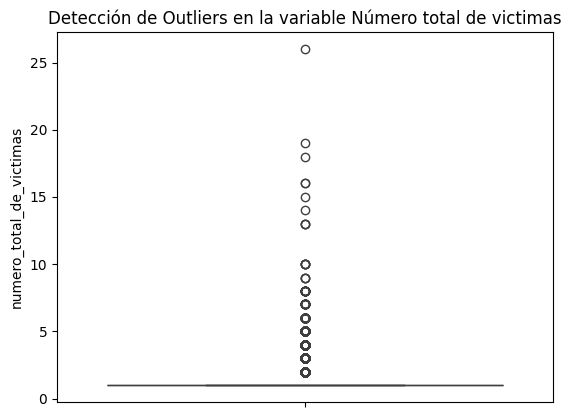

In [21]:
sns.boxplot(data=df_siniestros_modificado, y="numero_total_de_victimas")
plt.title("Detección de Outliers en la variable Número total de victimas")
plt.show()

In [22]:
df_siniestros_modificado[df_siniestros_modificado["numero_total_de_victimas"] == 26]

,id_siniestro,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,hora_siniestro,rango_horario,direccion_normalizada_siniestro,comuna_siniestro,longitud_siniestro,latitud_siniestro,participantes_siniestro,modo_desplazamiento_victima,contraparte_siniestro,gravedad_siniestro
46562,LC-2024-0243962,26.0,26,0,0,2024-04-30,2024,4,30,12:30:00,12.0,"ROCA, CNEL. AV. y COSQUIN",8.0,-58.465313,-34.693875,SD-SD,SD,SD,LEVE


In [23]:
columnas_victimas = [
    "numero_total_de_victimas",
    "numero_victimas_leve_siniestro",
    "numero_victimas_grave_siniestro",
    "numero_victimas_mortal_siniestro"
]

# Excluyo temporalmente los registros con valores nulos
df_victimas_completas = df_siniestros_modificado.dropna(
    subset=columnas_victimas
)

# Busco inconsistencias entre el total y la suma de víctimas
inconsistencias_victimas = df_victimas_completas[
    df_victimas_completas["numero_total_de_victimas"] != (
        df_victimas_completas["numero_victimas_leve_siniestro"]
        + df_victimas_completas["numero_victimas_grave_siniestro"]
        + df_victimas_completas["numero_victimas_mortal_siniestro"]
    )
]

display(inconsistencias_victimas[columnas_victimas])
print("Registros inconsistentes:", len(inconsistencias_victimas))

,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro
58435,4.0,5,0,0
63938,2.0,0,0,1


Registros inconsistentes: 2


El análisis de `numero_total_de_victimas` mostró una fuerte concentración de siniestros con una sola víctima y algunos valores atípicos, incluido uno con 26 víctimas leves.
Se revisó este caso y se comprobó que el total de víctimas coincide con la suma de las categorías leve, grave y mortal, sin encontrar evidencias para considerarlo un error.
Adicionalmente, se verificó la consistencia entre el total de víctimas y la suma de las categorías y en este caso, se identificaron dos registros inconsistentes con diferencias de una víctima.
La decisión fue conservar estos registros, sin imputar ni corregir valores, ya que no existe información suficiente para determinar los datos correctos. Además, el objetivo del modelo será predecir la cantidad de siniestros, no la de víctimas.

De esta manera, se evita eliminar siniestros potencialmente válidos por valores extremos o inconsistencias en variables que no se utilizarán como predictores.

# Análisis Exploratorio de Datos (EDA)

##### **Distribución de siniestros por comuna**

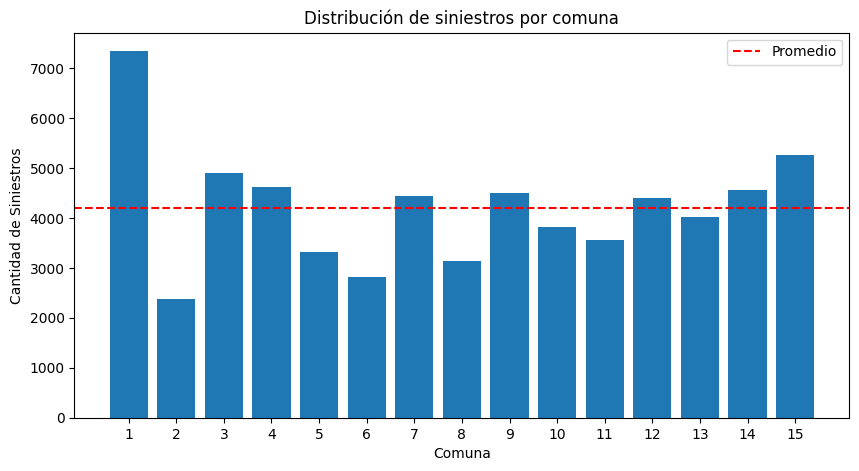

In [24]:
# Cuento la cantidad de siniestros por comuna y los ordeno por número de comuna.
conteo_comunas = df_siniestros_modificado["comuna_siniestro"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

# Convierto los números de comuna a int y luego a texto para mostrarlos como categorías el eje x, mejorando la visualización.
# El primer paso a int es para que se vea como 1 y no como 1.0.
plt.bar(conteo_comunas.index.astype(int).astype(str), conteo_comunas.values, width=0.8)
plt.title("Distribución de siniestros por comuna")
plt.xlabel("Comuna")
plt.ylabel("Cantidad de Siniestros")
# Muestro una referencia al promedio de siniestros.
plt.axhline(y=conteo_comunas.mean(), linestyle="--", label="Promedio", color="red")
plt.legend()
plt.show()

La Comuna 1 muestra una clara concentración de siniestros, muy por encima del promedio, mientras que la Comuna 2 es la que registra menor cantidad.
La línea de promedio se utiliza únicamente como referencia para comparar la cantidad de siniestros registrados entre las comunas.

##### **Distribución de siniestros por año**

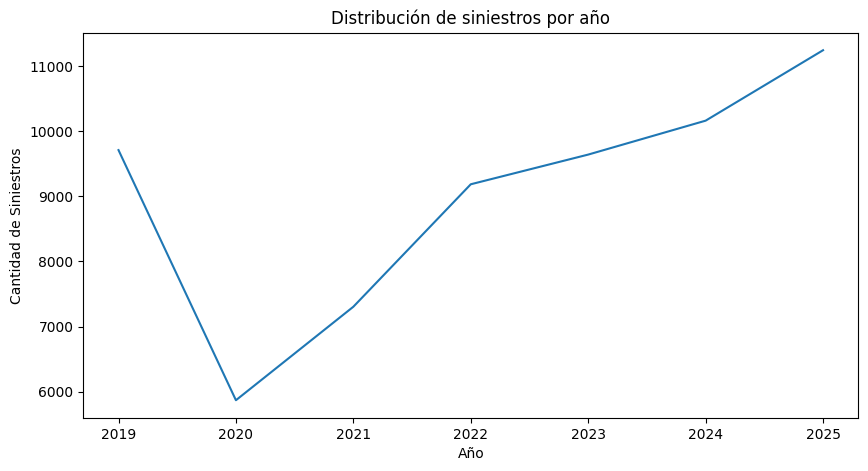

In [25]:
# Cuento la cantidad de siniestros por año y los ordeno.
conteo_anios = df_siniestros_modificado["anio_siniestro"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.plot(conteo_anios.index, conteo_anios.values)
plt.title("Distribución de siniestros por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de Siniestros")
plt.show()

Se observa una caída marcada en 2020, probablemente asociada a la pandemia y las restricciones de circulación. A partir de 2021 vuelve a aumentar la cantidad de siniestros y se observa una tendencia creciente hasta 2025.

##### **Distribución de siniestros por mes y año**

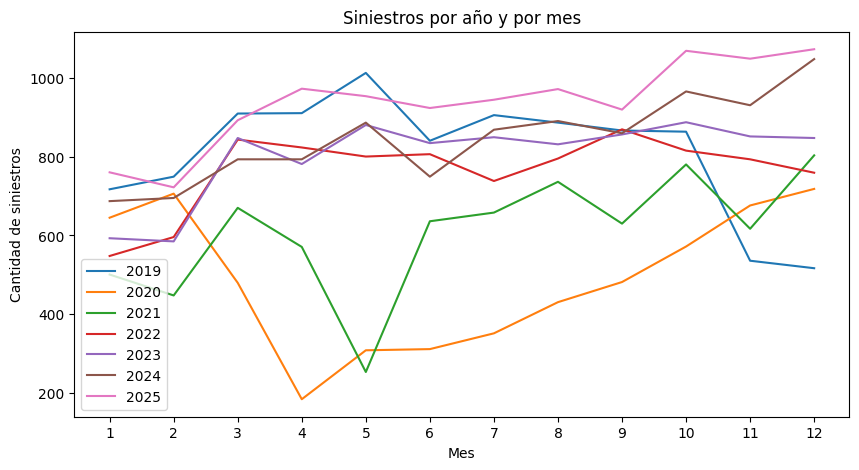

In [26]:
# Cuento la cantidad de siniestros por mes y los ordeno.
df_siniestros_grouped = df_siniestros_modificado.groupby("anio_siniestro")
conteo_meses = df_siniestros_grouped["mes_siniestro"].value_counts().sort_index()
conteo_meses_tabla = conteo_meses.unstack()

plt.figure(figsize=(10, 5))
for anio in conteo_meses_tabla.index:
    plt.plot(conteo_meses_tabla.loc[anio].index, conteo_meses_tabla.loc[anio].values, label=anio)
plt.xlabel("Mes")
plt.ylabel("Cantidad de siniestros")
plt.title("Siniestros por año y por mes")
plt.xticks(range(1, 13))
plt.legend()

plt.show()

Al comparar la evolución mensual por año, se observa que 2020 y 2021 presentan comportamientos diferentes al resto (probablemente explicados por la pandemia).
A partir de 2022 se aprecia un patrón más estable, con una tendencia general a registrar una mayor cantidad de siniestros durante la segunda mitad del año, aunque existen variaciones entre los distintos años.

El próximo paso será validar la hipótesis: **¿Hay más siniestros en la segunda mitad del año?**

In [27]:
conteo_meses_total = df_siniestros_modificado["mes_siniestro"].value_counts().sort_index()
conteo_meses_total_primera_mitad = conteo_meses_total.loc[conteo_meses_total.index <= 6].sum()
conteo_meses_total_segunda_mitad = conteo_meses_total.loc[conteo_meses_total.index > 6].sum()
print(f"Siniestros durante la primera mitad del año: {conteo_meses_total_primera_mitad}, segunda mitad: {conteo_meses_total_segunda_mitad}")

conteo_meses_tabla["total_primera_mitad"] = conteo_meses_tabla.loc[:,1:6].sum(axis=1)
conteo_meses_tabla["total_segunda_mitad"] = conteo_meses_tabla.loc[:,7:12].sum(axis=1)
conteo_meses_tabla["porcentaje_variacion"] = (conteo_meses_tabla["total_segunda_mitad"] - conteo_meses_tabla["total_primera_mitad"]) / conteo_meses_tabla["total_primera_mitad"] * 100
conteo_meses_tabla[["total_primera_mitad", "total_segunda_mitad", "porcentaje_variacion"]]


Siniestros durante la primera mitad del año: 29615, segunda mitad: 33499


mes_siniestro,total_primera_mitad,total_segunda_mitad,porcentaje_variacion
anio_siniestro,,,
2019,5137,4573,-10.979171
2020,2637,3231,22.525597
2021,3080,4224,37.142857
2022,4416,4769,7.993659
2023,4520,5121,13.296460
2024,4603,5559,20.769064
2025,5222,6022,15.319801


Los números obtenidos en este análisis refuerzan lo interpretado en los gráficos. Durante la segunda mitad del año se observa un patrón de mayor cantidad de siniestros, con la única excepción de 2019 donde la cantidad se redujo.

##### **Distribución de siniestros por día de la semana**

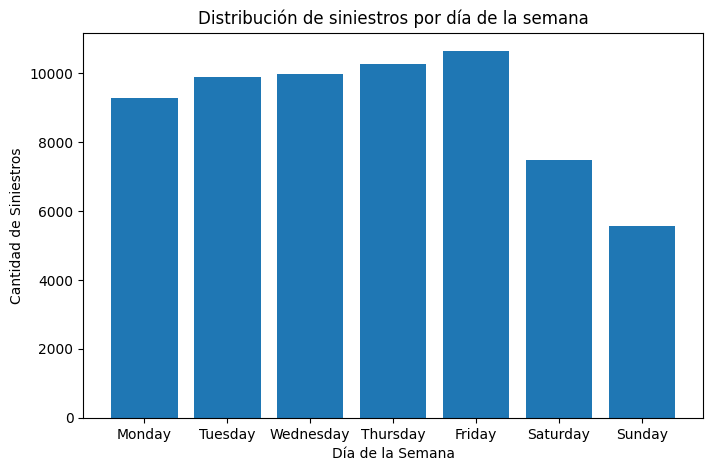

In [28]:
df_siniestros_modificado["dia_semana_siniestro"] = df_siniestros_modificado["fecha_siniestro"].dt.day_name()
dias_semana = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
serie_ordenada = df_siniestros_modificado["dia_semana_siniestro"].value_counts().reindex(dias_semana)

plt.figure(figsize=(8, 5))
plt.bar(serie_ordenada.index, serie_ordenada.values)
plt.title("Distribución de siniestros por día de la semana")
plt.xlabel("Día de la Semana")
plt.ylabel("Cantidad de Siniestros")
plt.show()


##### **Distribución de siniestros por año y día de la semana**

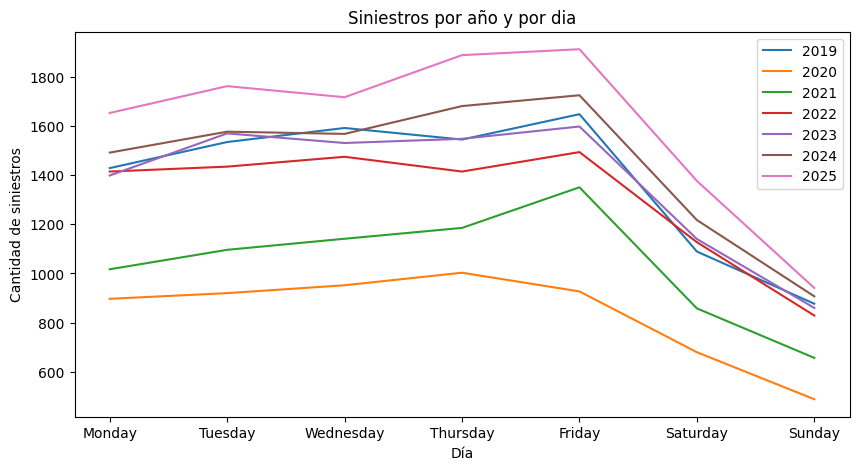

In [29]:
conteo_dias_por_anio = df_siniestros_modificado.groupby("anio_siniestro")["dia_semana_siniestro"].value_counts()
conteo_dias_por_anio_tabla = conteo_dias_por_anio.unstack()
conteo_dias_por_anio_tabla = conteo_dias_por_anio_tabla[dias_semana]

plt.figure(figsize=(10, 5))
for dia in conteo_dias_por_anio_tabla.index:
    plt.plot(conteo_dias_por_anio_tabla.loc[dia].index, conteo_dias_por_anio_tabla.loc[dia].values, label=dia)
plt.xlabel("Día")
plt.ylabel("Cantidad de siniestros")
plt.title("Siniestros por año y por dia")
plt.xticks(range(len(dias_semana)), dias_semana)
plt.legend()

plt.show()

El análisis muestra un pico de siniestros los viernes y una fuerte caída los sábados y especialmente los domingos. El mismo comportamiento se observa a lo largo de todos los años analizados.

##### **Distribución de siniestros por hora**

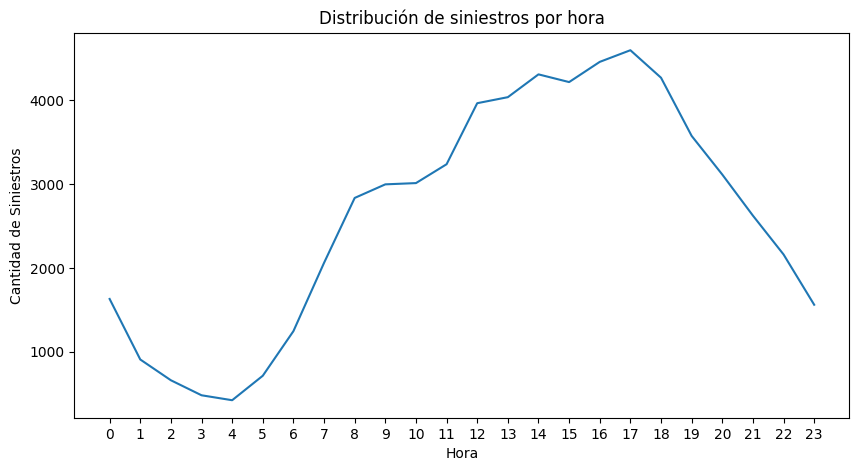

In [30]:
# Cuento la cantidad de siniestros por hora y los ordeno.
conteo_horas = df_siniestros_modificado["rango_horario"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.plot(conteo_horas.index, conteo_horas.values)
plt.title("Distribución de siniestros por hora")
plt.xlabel("Hora")
plt.ylabel("Cantidad de Siniestros")
plt.xticks(range(0, 24))
plt.show()

La cantidad de siniestros es menor durante la madrugada, alcanzando su punto mínimo alrededor de las 4 hs. A partir de las primeras horas de la mañana comienza a aumentar, alcanzando su pico máximo a las 17 hs.
Durante la noche comienza a descender progresivamente.
El pico observado durante la tarde podría estar relacionado con horarios de mayor circulación, aunque sería necesario contar con datos de volumen de tránsito para comprobar esta relación.

##### **Distribución de siniestros por día y hora**

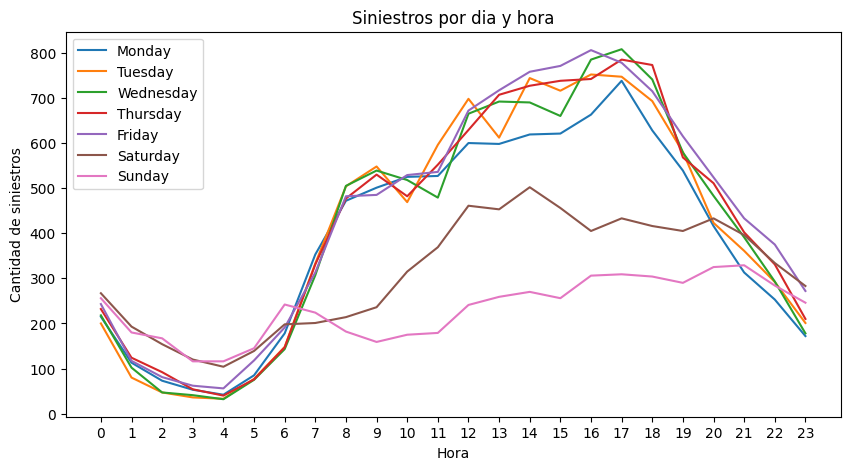

In [31]:
conteo_dias_por_dia_hora = df_siniestros_modificado.groupby("dia_semana_siniestro")["rango_horario"].value_counts()
conteo_dias_por_dia_hora_tabla = conteo_dias_por_dia_hora.unstack()
conteo_dias_por_dia_hora_tabla = conteo_dias_por_dia_hora_tabla.reindex(dias_semana)

plt.figure(figsize=(10, 5))
for dia in conteo_dias_por_dia_hora_tabla.index:
    plt.plot(conteo_dias_por_dia_hora_tabla.loc[dia].index, conteo_dias_por_dia_hora_tabla.loc[dia].values, label=dia)
plt.xlabel("Hora")
plt.ylabel("Cantidad de siniestros")
plt.title("Siniestros por dia y hora")
plt.xticks(range(0, 24))
plt.legend()

plt.show()

La distribución horaria de los siniestros se comporta de manera diferente entre los días de semana y los fines de semana. De lunes a viernes se observa un patrón similar, con aumento durante la mañana y mayor concentración por la tarde.

En cambio, durante el fin de semana el comportamiento cambia. El sábado presenta su mayor concentración más temprano que los días laborales. El domingo muestra una cantidad considerablemente menor de siniestros durante gran parte del día, sin embargo, durante la madrugada sus valores son más similares a los del resto de la semana.

##### **Análisis espacial de los siniestros**

###### Distribución geográfica de los siniestros

Los CRS son iguales


Text(0.5, 1.0, 'Siniestros por km²')

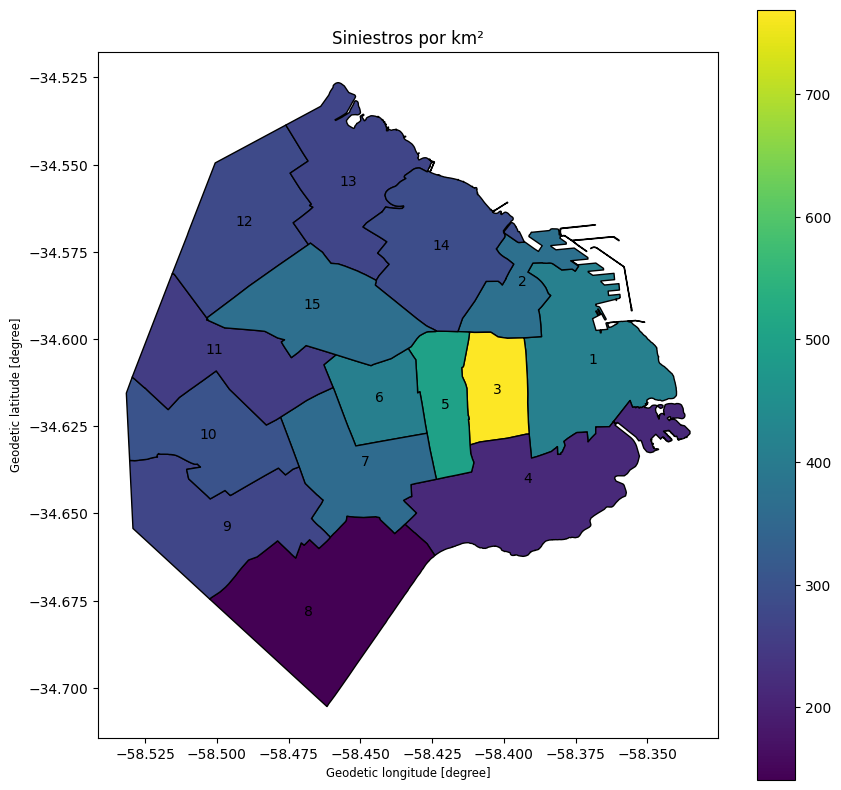

In [32]:
# Para trabajar en los gráficos geo espaciales, elimino los registros con valores NaN
# Uso el crs EPSG:4326 que es el habitual para coordenadas expresadas en longitud y latitud.
df_geo = df_siniestros_modificado.dropna(subset=["longitud_siniestro", "latitud_siniestro"])
gdf_siniestros = gpd.GeoDataFrame(df_geo,
    geometry=gpd.points_from_xy(df_geo["longitud_siniestro"], df_geo["latitud_siniestro"]), crs=CRS_COORDENADAS
)

conteo_comunas_df = conteo_comunas.reset_index()

if gdf_siniestros.crs == gdf_comunas.crs:
    print("Los CRS son iguales")
else:
    gdf_comunas = gdf_comunas.to_crs(CRS_COORDENADAS)

gdf_comunas = gdf_comunas.merge(conteo_comunas_df, left_on="comuna", right_on="comuna_siniestro")

gdf_comunas["area_km2"] = gdf_comunas["area"] / 1_000_000
gdf_comunas["siniestros_por_km2"] = gdf_comunas["count"] / gdf_comunas["area_km2"]

ax = gdf_comunas.plot(figsize=(10, 10), edgecolor="black", column="siniestros_por_km2", legend=True)
for _, row in gdf_comunas.iterrows():
    punto = row.geometry.representative_point()
    ax.text(
        punto.x,
        punto.y,
        str(row["comuna"]),
        ha="center",
        va="center"
    )
ax.set_title("Siniestros por km²")


Al considerar la superficie de cada comuna, la distribución cambia respecto del análisis basado únicamente en las cantidades de siniestros. La **Comuna 3** presenta la mayor cantidad de siniestros por km², seguida por la **Comuna 5**, ubicada geográficamente junto a ella. Luego se encuentran las **Comunas 1 y 6**.
En el extremo opuesto, la **Comuna 8** presenta la menor cantidad de siniestros por km².

# Feature Engineering
El dataset original contiene un registro por siniestro. Sin embargo, el objetivo del modelo es predecir la cantidad de siniestros esperados para una combinación de lugar y momento.
Por ese motivo, los registros se agruparán por `fecha`, `comuna` y `franja_horaria`.
La información por horas se agrupará en intervalos de 4 horas para reducir la granularidad de la variable y permitir identificar patrones horarios más generales.

In [33]:
# right=False incluye el límite izquierdo y excluye el derecho de cada intervalo. Hago esto porque los valores son desde 0 hasta 23.
df_siniestros_modificado["franja_horaria"] = pd.cut(df_siniestros_modificado["rango_horario"], bins=[0, 4, 8, 12, 16, 20, 24], labels=["0-4", "4-8", "8-12", "12-16", "16-20", "20-24"], right=False)
df_siniestros_modificado["franja_horaria"].unique()

['0-4', '16-20', '12-16', '4-8', '8-12', '20-24']
Categories (6, object): ['0-4' < '4-8' < '8-12' < '12-16' < '16-20' < '20-24']

In [34]:
# observed=False le indica al groupby que incluya también las categorías que no fueron observadas en una combinación determinada.
siniestros_grouped = df_siniestros_modificado.groupby(["fecha_siniestro", "comuna_siniestro", "franja_horaria"], observed=False)
cantidad_siniestros_agrupados = siniestros_grouped.size()
delta_fechas_df = df_siniestros_modificado["fecha_siniestro"].max() - df_siniestros_modificado["fecha_siniestro"].min()

fechas_presentes = df_siniestros_modificado["fecha_siniestro"].nunique()
fechas_esperadas = delta_fechas_df.days + 1

assert fechas_presentes == fechas_esperadas, "Hay fechas faltantes"

cantidad_esperada = fechas_esperadas * df_siniestros_modificado["comuna_siniestro"].nunique() * df_siniestros_modificado["franja_horaria"].nunique()
if cantidad_siniestros_agrupados.size == cantidad_esperada:
    print("Están representadas todas las combinaciones de fecha, comuna y franja horaria del período incluido en el dataset")
    # En este caso iría por acá, pero lo evalúo por si había que realizar modificaciones.
else:
    print("No están representadas todas las combinaciones de fecha, comuna y franja horaria del período incluido en el dataset")

df_siniestros_agrupados = cantidad_siniestros_agrupados.reset_index()
df_siniestros_agrupados = df_siniestros_agrupados.rename(columns={0: "cantidad_de_siniestros"})
df_siniestros_agrupados["anio"] = df_siniestros_agrupados["fecha_siniestro"].dt.year
df_siniestros_agrupados["mes"] = df_siniestros_agrupados["fecha_siniestro"].dt.month
df_siniestros_agrupados["dia_semana"] = df_siniestros_agrupados["fecha_siniestro"].dt.day_name()
df_siniestros_agrupados["cantidad_de_siniestros"].value_counts()

Están representadas todas las combinaciones de fecha, comuna y franja horaria del período incluido en el dataset


,count
cantidad_de_siniestros,
0,178884
1,41448
2,8077
3,1430
4,243
5,41
6,5
8,1
7,1


El dataset resultante contiene una fila por cada combinación de `fecha`, `comuna` y `franja horaria`. Las combinaciones en las que no se registraron siniestros se mantienen igual con conteo igual a cero, ya que representan períodos y zonas en las que el evento de interés no ocurrió.
A partir de la fecha se generan además las variables `anio`, `mes` y `dia_semana`, que permitirán incorporar patrones temporales al modelo.

La variable objetivo, **cantidad_de_siniestros**, presenta una distribución fuertemente concentrada en valores bajos. De las 230.130 combinaciones de fecha, comuna y franja horaria, el 78% (178.884 registros) no registran siniestros, mientras que la mayoría de las restantes presentan solo uno o dos.
Esta concentración de ceros deberá tenerse en cuenta durante el modelado y la evaluación.

# Modelado

### Preparación de las variables para el modelo
Las variables `comuna_siniestro`, `franja_horaria`, `mes` y `dia_semana` representan categorías y serán transformadas mediante **One-Hot Encoding**. Al ser todas variables categóricas, no es necesario aplicar normalización ni estandarización.

La transformación se incorpora dentro de un **Pipeline**.

**Estrategia**  
Para evaluar la capacidad del modelo de generalizar períodos futuros, se realizará una separación temporal de los datos. Los años anteriores a 2025 se utilizarán para entrenamiento y 2025 se reservará como conjunto de prueba.

In [35]:
variable_objetivo = "cantidad_de_siniestros"
y = df_siniestros_agrupados[variable_objetivo]
x = df_siniestros_agrupados[["comuna_siniestro", "franja_horaria", "mes", "dia_semana"]]

categorical_features = ["comuna_siniestro", "franja_horaria", "mes", "dia_semana"]

# Guardo 2025 para usar como test.
X_train = x.loc[df_siniestros_agrupados["anio"] < 2025]
X_test = x.loc[df_siniestros_agrupados["anio"] == 2025]
y_train = y.loc[df_siniestros_agrupados["anio"] < 2025]
y_test = y.loc[df_siniestros_agrupados["anio"] == 2025]

# Valido que X e Y tengan la misma cantidad de valores para entrenar
if len(X_train) == len(y_train):
    print("Cantidad correcta.")
else:
    print("Cantidad incorrecta, error.")


# Valido que X e Y tengan la misma cantidad de valores para testear
if len(X_test) == len(y_test):
    print("Cantidad correcta.")
else:
    print("Cantidad incorrecta, error.")

# Preparo el preprocesamiento que luego incluiré en mi pipeline
# remainder="passthrough" es para que las columnas que no se transforman, pasen sin cambios y se mantengan en el df
# force_int_remainder_cols=False elimina un warning que aparece por un cambio en la próxima versión

preprocessor = ColumnTransformer(
    transformers=[
        # handle_unknown="ignore" es para evitar errores si aparecen categorías nuevas.
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],

    remainder="passthrough",
    force_int_remainder_cols=False
)

Cantidad correcta.
Cantidad correcta.


## **PoissonRegressor**



In [36]:
model = PoissonRegressor(alpha=0.1)
model

PoissonRegressor(alpha=0.1)

### Entrenamiento y prueba del modelo

In [37]:
pipeline_poisson = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

pipeline_poisson.fit(X_train, y_train)

y_predicted_poisson = pipeline_poisson.predict(X_test)
print(f"Predicciones generadas: {len(y_predicted_poisson)}")

Predicciones generadas: 32850


En la primera ejecución del modelo se incluyó `anio` como variable numérica junto con las variables categóricas. Al analizar las predicciones se observó que el modelo devolvía prácticamente el mismo valor para todas las observaciones y que sus coeficientes eran iguales a cero.
Como parte del diagnóstico se retiró temporalmente `anio` de las variables predictoras. Al volver a entrenar al modelo, los coeficientes dejaron de ser cero y las predicciones comenzaron a variar entre las distintas observaciones.

### Evaluación del Modelo
Los resultados sobre el conjunto de prueba 2025 se presentan para analizar el desempeño de cada modelo. La selección final se realiza utilizando exclusivamente los resultados de la validación cruzada temporal sobre el periodo 2019-2024.

#### MAE

In [38]:
MAE_poisson = mean_absolute_error(y_test, y_predicted_poisson)
print(f"MAE Poisson: {MAE_poisson}")

# Como primer baseline se utiliza una predicción constante de cero siniestros para todas las combinaciones.
y_predicted_baseline = np.zeros(len(y_test))
MAE_baseline = mean_absolute_error(y_test, y_predicted_baseline)
print(f"MAE Baseline: {MAE_baseline}")

display(pd.Series(y_predicted_poisson).describe())

MAE Poisson: 0.451610799582849
MAE Baseline: 0.34228310502283105


,0
count,32850.000000
mean,0.263010
std,0.043440
min,0.173918
25%,0.223613
50%,0.262652
75%,0.300439
max,0.372085


#### MSE

In [39]:
MSE_poisson = mean_squared_error(y_test, y_predicted_poisson)
print(f"MSE Poisson: {MSE_poisson:.4f}")
MSE_baseline = mean_squared_error(y_test, y_predicted_baseline)
print(f"MSE Baseline: {MSE_baseline:.4f}")

MSE Poisson: 0.3931
MSE Baseline: 0.5197


#### Cálculo Lift@10

In [40]:
lift_10_poisson = calcular_lift(y_test, y_predicted_poisson, 0.10)
print(f"Lift@10 Poisson: {lift_10_poisson:.4f}")

Lift@10 Poisson: 2.2599


### **Conclusión**
El modelo Poisson obtuvo un MAE de aproximadamente 0,45 siniestros, mientras que el modelo baseline, que predice siempre cero siniestros, obtiene un MAE menor de 0,34 siniestros aproximadamente.
Este resultado está relacionado con la fuerte concentración de ceros en la variable objetivo, un 78% aproximadamente de las combinaciones no registra ningún siniestro.
Como el MAE favorece predecir la mediana, que en este caso es cero, se incorporó también el MSE, que favorece predecir el valor promedio y penaliza más los errores en las combinaciones con varios siniestros. Con esta métrica, el resultado se invirtió, el modelo Poisson obtuvo un MSE de 0,39 frente a 0,52 del baseline.
Igualmente, para el objetivo planteado interesa la capacidad de identificar las combinaciones de mayor riesgo y por eso se utilizó el Lift, que compara el promedio de siniestros en las combinaciones con predicciones más altas contra el promedio general.

## **XGBoost Regressor**

### Preparación del Modelo

In [41]:
model_xgb = xgb.XGBRegressor(random_state=42)
pipeline_xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_xgb)
])
pipeline_xgb.fit(X_train, y_train)

predict_xgb = pipeline_xgb.predict(X_test)

print(f"Predicciones generadas: {len(predict_xgb)}")

Predicciones generadas: 32850


### Evaluación del Modelo

#### MAE

In [42]:
mae_xgb = mean_absolute_error(y_test, predict_xgb)
print(f"MAE XGBoost: {mae_xgb}")

MAE XGBoost: 0.41259196400642395


#### MSE

In [43]:
mse_xgb = mean_squared_error(y_test, predict_xgb)
print(f"MSE XGBoost: {mse_xgb}")

MSE XGBoost: 0.36348119378089905


#### Cálculo Lift@10

In [44]:
lift_10_xgb = calcular_lift(y_test, predict_xgb, 0.10)
print(f"Lift@10% XGBRegressor: {lift_10_xgb}")
lift_5_xgb = calcular_lift(y_test, predict_xgb, 0.05)
print(f"Lift@5% XGBRegressor: {lift_5_xgb}")
lift_20_xgb = calcular_lift(y_test, predict_xgb, 0.20)
print(f"Lift@20% XGBRegressor: {lift_20_xgb}")

Lift@10% XGBRegressor: 2.25809320526503
Lift@5% XGBRegressor: 2.6119655208721957
Lift@20% XGBRegressor: 1.9841693347563145


## Validación Cruzada y optimización de hiperparámetros

### GridSearchCV

In [45]:
# Diccionario

grid_search_params = {
    "model__max_depth": [3, 5],
    "model__n_estimators": [100, 200]
}

# Preparación de los datos

anios_train = df_siniestros_agrupados.loc[X_train.index, "anio"]

anios_train_1 = anios_train <= 2021
anios_val_1 = anios_train == 2022
anios_train_2 = anios_train <= 2022
anios_val_2 = anios_train == 2023
anios_train_3 = anios_train <= 2023
anios_val_3 = anios_train == 2024

train_index_1 = np.where(anios_train_1)[0]
val_index_1 = np.where(anios_val_1)[0]
train_index_2 = np.where(anios_train_2)[0]
val_index_2 = np.where(anios_val_2)[0]
train_index_3 = np.where(anios_train_3)[0]
val_index_3 = np.where(anios_val_3)[0]

cv_splits = [(train_index_1, val_index_1), (train_index_2, val_index_2), ( train_index_3, val_index_3)]

estimator = pipeline_xgb

grid_search = GridSearchCV(estimator=pipeline_xgb, param_grid=grid_search_params, cv=cv_splits, scoring="neg_mean_absolute_error")
grid_search.fit(X_train, y_train)

GridSearchCV(cv=[(array([    0,     1,     2, ..., 98637, 98638, 98639]),
                  array([ 98640,  98641,  98642, ..., 131487, 131488, 131489])),
                 (array([     0,      1,      2, ..., 131487, 131488, 131489]),
                  array([131490, 131491, 131492, ..., 164337, 164338, 164339])),
                 (array([     0,      1,      2, ..., 164337, 164338, 164339]),
                  array([164340, 164341, 164342, ..., 197277, 197278, 197279]))],
             estimator=Pipeline(steps=[('preprocessor',
                                        Colum...
                                                     max_bin=None,
                                                     max_cat_threshold=None,
                                                     max_cat_to_onehot=None,
                                                     max_delta_step=None,
                                                     max_depth=None,
                                                     max_leaves=None,
                                                     min_child_weight=None,
                                                     missing=nan,
                                                     monotone_constraints=None,
                                                     multi_strategy=None,
                                                     n_estimators=None,
                                                     n_jobs=None,
                                                     num_parallel_tree=None, ...))]),
             param_grid={'model__max_depth': [3, 5],
                         'model__n_estimators': [100, 200]},
             scoring='neg_mean_absolute_error')

In [46]:
print(f"Best Params: {grid_search.best_params_}")

print(f"Best Score: {grid_search.best_score_ * -1}")

# Pruebo con los mejores resultados

best_model = grid_search.best_estimator_
predict_best_model = best_model.predict(X_test)

# MAE
mae_xgb_best_model = mean_absolute_error(y_test, predict_best_model)
print(f"MAE Best Model: {mae_xgb_best_model}")

#MSE
mse_xgb_best_model = mean_squared_error(y_test, predict_best_model)
print(f"MSE Best Model: {mse_xgb_best_model}")

# Lift@10%
lift10_best_model = calcular_lift(y_test, predict_best_model, 0.10)
print(f"Lift@10% Best Model: {lift10_best_model}")
# Lift@5%
lift5_best_model = calcular_lift(y_test, predict_best_model, 0.05)
print(f"Lift@5% Best Model: {lift5_best_model}")
# Lift@20%
lift20_best_model = calcular_lift(y_test, predict_best_model, 0.20)
print(f"Lift@20% Best Model: {lift20_best_model}")

Best Params: {'model__max_depth': 5, 'model__n_estimators': 100}
Best Score: 0.38014442722002667
MAE Best Model: 0.4128962755203247
MSE Best Model: 0.36266136169433594
Lift@10% Best Model: 2.2936677339025255
Lift@5% Best Model: 2.651109418323959
Lift@20% Best Model: 1.9837246531483457


## **XGBoost Regressor con objetivo Poisson**

### Preparación del Modelo

In [47]:
model_xgb_poisson = xgb.XGBRegressor(random_state=42, objective="count:poisson")
pipeline_xgb_poisson = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_xgb_poisson)
])
pipeline_xgb_poisson

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(force_int_remainder_cols=False,
                                   remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['comuna_siniestro',
                                                   'franja_horaria', 'mes',
                                                   'dia_semana'])])),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_byt...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, ...))])

## **Baseline de promedio histórico**
Para saber si el modelo aporta valor, lo comparo contra un baseline (una predicción simple que no requiere entrenamiento).
El Baseline de Ceros que utilicé con el modelo Poisson no sirve para evaluar el Lift ya que predice el mismo valor para todas las combinaciones y no permite ordenarlas por riesgo.
Por este motivo, agrego un segundo Baseline en el que por cada combinación de comuna, franja horaria y día de la semana, predice el promedio de siniestros registrados. Si los modelos no superan a este Baseline, el uso de ML no se justifica.
Para que la comparación sea justa, evaluaré al baseline con los mismos folds temporales que a los modelos.

In [48]:
MAE_historico = []
MSE_historico = []
lift5_historico = []

for train_index, val_index in cv_splits:
    X_train_fold = X_train.iloc[train_index]
    X_val_fold = X_train.iloc[val_index]

    y_train_fold = y_train.iloc[train_index]
    y_val_fold = y_train.iloc[val_index]

    predict_historico = baseline_historico(X_train_fold, y_train_fold, X_val_fold, COLUMNAS_BASELINE)

    MAE_historico.append(mean_absolute_error(y_val_fold, predict_historico))
    MSE_historico.append(mean_squared_error(y_val_fold, predict_historico))
    lift5_historico.append(calcular_lift(y_val_fold, predict_historico, 0.05))

print(f"MAE promedio baseline histórico: {np.mean(MAE_historico):.4f}")
print(f"MSE promedio baseline histórico: {np.mean(MSE_historico):.4f}")
print(f"Lift@5% promedio baseline histórico: {np.mean(lift5_historico):.4f}")

MAE promedio baseline histórico: 0.3800
MSE promedio baseline histórico: 0.3138
Lift@5% promedio baseline histórico: 2.5370


## Comparación de modelos mediante validación cruzada

In [49]:
# Evalúo todos los modelos con los folds temporales

resultados_cv = {
    "Baseline Histórico": (MAE_historico, MSE_historico, lift5_historico),
    "Poisson": evaluar_cv(pipeline_poisson, X_train, y_train, cv_splits),
    "XGBoost Original": evaluar_cv(pipeline_xgb, X_train, y_train, cv_splits),
    "XGBoost Optimizado": evaluar_cv(grid_search.best_estimator_, X_train, y_train, cv_splits),
    "XGBoost con Poisson": evaluar_cv(pipeline_xgb_poisson, X_train, y_train, cv_splits),
}

filas = []
for nombre, (MAE_folds, MSE_folds, lift5_folds) in resultados_cv.items():
    filas.append({
        "Modelo": nombre,
        "MAE": np.mean(MAE_folds),
        "MSE": np.mean(MSE_folds),
        "Lift@5%": np.mean(lift5_folds)
    })

    df_resultados = pd.DataFrame(filas)
df_resultados.round(4)

,Modelo,MAE,MSE,Lift@5%
0,Baseline Histórico,0.3800,0.3138,2.5370
1,Poisson,0.4126,0.3364,2.5053
2,XGBoost Original,0.3801,0.3165,2.4002
3,XGBoost Optimizado,0.3801,0.3147,2.4878
4,XGBoost con Poisson,0.3800,0.3141,2.4863


En esta evaluación, el **Baseline Histórico** obtiene resultados iguales o levemente mejores que todos los modelos en las tres métricas: empata en MAE (0,3800), tiene el menor MSE (0,3138) y el mayor Lift@5% (2,5370).
Con las variables disponibles (comuna, franja horaria, día de la semana y mes), los modelos no logran superar a un promedio calculado por combinación.

Entre los modelos, **XGBoost con Poisson** obtiene el mejor MAE (0,3800) y el menor MSE (0,3141), con un Lift@5% prácticamente igual al del XGBoost Optimizado (2,49 aproximadamente).
El modelo Poisson obtiene un Lift@5% mayor (2,5053) pero el peor MSE (0,3364), lo que significa que ordena correctamente las combinaciones de mayor riesgo, pero estima con menos precisión la cantidad de siniestros.

## Entrenamiento final del modelo seleccionado: **XGBoost con Poisson**
Seleccioné **XGBoost con objetivo Poisson** como modelo final en base a los resultados obtenidos en la validación cruzada temporal sobre el período 2019-2024, sin utilizar los datos de prueba de 2025 para la selección.
Entre los modelos evaluados obtuvo el menor MAE (0,3800) y MSE (0,3141) y un Lift@5% (2,4863) equivalente al del modelo optimizado.
Como ambos modelos tuvieron resultados muy similares, seleccioné el objetivo Poisson ya que es el adecuado para una variable de conteo y garantiza predicciones no negativas.
Si bien el modelo no supera al baseline de promedio histórico, lo mantengo igual como modelo final ya que el baseline funciona con pocas variables, pero si se agregan más, cada combinación quedaría con muy pocos datos y el promedio dejaría de ser confiable. En cambio, el modelo sí puede incorporar variables nuevas.

In [50]:
pipeline_xgb_poisson.fit(X_train, y_train)
predict_modelo_final = pipeline_xgb_poisson.predict(X_test)
print(f"Predicciones generadas: {len(predict_modelo_final)}")

Predicciones generadas: 32850


In [51]:
# Predicción del baseline histórico para 2025, calculado con todo el periodo de entrenamiento.
predict_historico_test = baseline_historico(X_train, y_train, X_test, COLUMNAS_BASELINE)

predicciones_2025 = {
    "Baseline Ceros": y_predicted_baseline,
    "Baseline Histórico": predict_historico_test,
    "XGBoost con Poisson": predict_modelo_final
}

filas_2025 = []
for nombre, predicciones in predicciones_2025.items():
    filas_2025.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test, predicciones),
        "MSE": mean_squared_error(y_test, predicciones),
        "Lift@5%": calcular_lift(y_test, predicciones, 0.05)
    })

df_resultados_2025 = pd.DataFrame(filas_2025)
df_resultados_2025.round(4)

,Modelo,MAE,MSE,Lift@5%
0,Baseline Ceros,0.3423,0.5197,NaN
1,Baseline Histórico,0.4134,0.3629,2.5871
2,XGBoost con Poisson,0.4130,0.3623,2.6404


Para confirmar los resultados, evalué el modelo final con los datos de test de 2025.
XGBoost con Poisson obtuvo un Lift@5% de 2,6404, lo que significa que el 5% de las combinaciones con mayor predicción tuvieron en promedio 2,6 veces más siniestros que el promedio general.
Frente al Baseline Histórico quedó levemente adelante en las tres métricas, pero con diferencias muy chicas. Esto confirma lo que se vio en la Validación Cruzada: con las variables actuales, el modelo y el baseline tienen un desempeño similar.
El Baseline de Ceros vuelve a tener el menor MAE pero el mayor MSE, y no tiene Lift porque predice el mismo valor para todas las combinaciones y no permite ordenarlas.

# Interpretabilidad del modelado

### Método **importancia de las variables**

In [52]:
valores_variables = pipeline_xgb_poisson.named_steps["model"].feature_importances_

preprocessor_modelo = pipeline_xgb_poisson.named_steps["preprocessor"]
nombres_variables = preprocessor_modelo.get_feature_names_out()

df_importancia = pd.DataFrame({
    "variable": nombres_variables,
    "importancia": valores_variables
})

df_importancia = df_importancia.sort_values(by="importancia", ascending=False)

# Muestro las 10 variables más importantes
df_importancia.head(10)

,variable,importancia
15,cat__franja_horaria_0-4,0.184965
19,cat__franja_horaria_4-8,0.165711
0,cat__comuna_siniestro_1.0,0.099791
36,cat__dia_semana_Sunday,0.066283
18,cat__franja_horaria_20-24,0.063769
1,cat__comuna_siniestro_2.0,0.060645
35,cat__dia_semana_Saturday,0.035891
5,cat__comuna_siniestro_6.0,0.032162
14,cat__comuna_siniestro_15.0,0.026456
7,cat__comuna_siniestro_8.0,0.026093


Al analizar la importancia de las variables, se observa que varias de las categorías más relevantes para el modelo corresponden a las franjas horarias, las comunas y los días de la semana.
La franja de 0 a 4 hs es la que tiene mayor importancia individual. Sin embargo, en el análisis exploratorio vimos que es una de las franjas con menos siniestros. Esto muestra que en este caso es una categoría importante para el modelo pero no por identificar mayor concentración de siniestros, sino por ayudar a distinguir cuándo ocurren menos.

### Método **SHAP**

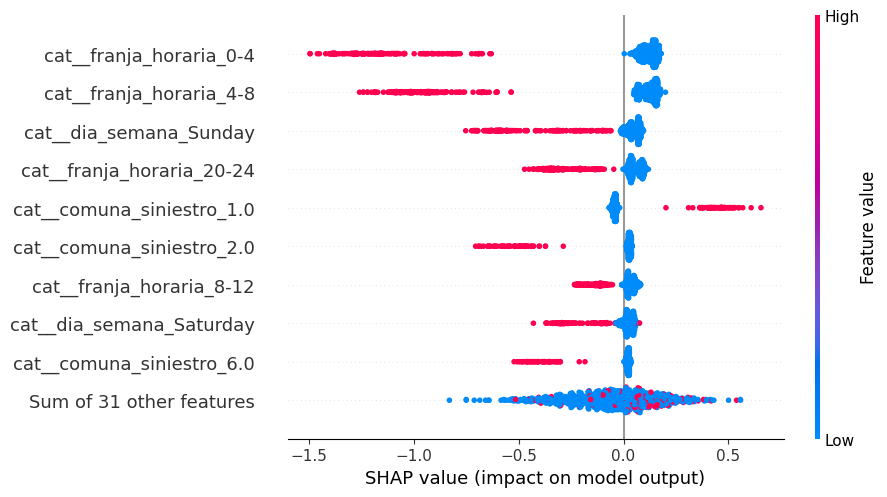

In [53]:
# Transformo X_test para que tenga la misma estructura que X_train

X_test_transformado = preprocessor_modelo.transform(X_test)
X_test_transformado.shape

explainer = shap.TreeExplainer(pipeline_xgb_poisson.named_steps["model"])

indices_random = X_test.sample(n=1000, random_state=42).index
X_shap = X_test_transformado[X_test.index.get_indexer(indices_random)]
shap_values = explainer(X_shap)
shap_values.feature_names = nombres_variables

shap.plots.beeswarm(shap_values)

**Interpretación del gráfico**
Las franjas de 0 a 4 y 4 a 8 horas son las que más influyen e impactan bajando la predicción. Esto confirma lo observado en la sección importancia de las variables, el modelo las usa para identificar cuándo ocurren menor cantidad de siniestros. Lo mismo pasa con el domingo, sábado y las comunas 2 y 6.
La comuna 1 es la única variable que sube la predicción de forma marcada, en línea con el EDA, donde se podía observar que esta comuna era la que tenía la mayor cantidad de siniestros.
El mes no aparece entre las variables que más aportan. Es la única variable que usa el modelo pero no el baseline histórico, lo que ayuda a explicar por qué ambos tienen un desempeño similar.

**Nota**: como el modelo usa objetivo Poisson, los valores SHAP están en escala logarítmica: un valor de -1 equivale a multiplicar la predicción por 0,37 aproximadamente.

# Conclusiones

El objetivo del trabajo fue predecir la cantidad de siniestros viales en CABA para cada combinación de fecha, comuna y franja horaria (agrupada en 4 hs), con el fin de identificar los momentos y zonas de mayor riesgo.
Después de limpiar los datos y recuperar 903 registros que inicialmente no tenían comuna asignada, armé un dataset de 230.130 combinaciones, de las cuales el 78 % no registraba siniestros.

#### **Respuestas a las preguntas de análisis**
1. ¿Cómo se distribuyen los siniestros según ubicación y momento?<br>
    La **Comuna 1** concentra la mayor cantidad de siniestros, aunque al considerar la superficie la **Comuna 3** es la de mayor densidad.
    En cuanto al momento del día, los siniestros se concentran mayormente por la tarde con un pico a las 17 hs, y se reducen durante la madrugada.
    Los días de semana registran más siniestros que los fines de semana, siendo el viernes el día más alto.
    A partir de 2022 también se observa una mayor cantidad de siniestros durante la segunda mitad del año.
2. ¿Qué patrones permiten identificar zonas y horarios de mayor ocurrencia?<br>
    La franja horaria es la variable más relevante, seguida por la comuna y el día de la semana. El análisis SHAP mostró que el modelo identifica principalmente las combinaciones de menor riesgo (madrugada, fines de semana, comunas 2 y 6), mientras que la Comuna 1 es la que más aumenta la predicción.
    El mes tuvo poca influencia.

#### **Resultado del modelo**
El modelo final, **XGBoost con objetivo Poisson**, obtuvo en 2025 un Lift@5% de 2,64, lo que significa que el 5 % de las combinaciones detectadas como de mayor riesgo tuvo en promedio 2,6 veces más siniestros que el promedio general. Para el uso planteado, que es priorizar dónde y cuándo concentrar controles, este es el resultado más relevante.
En la validación cruzada, el modelo no logró superar al baseline histórico. En los datos de prueba de 2025 obtuvo resultados ligeramente mejores en las tres métricas, aunque las diferencias fueron pequeñas. Esto indica que, con las variables actuales, ambos métodos tienen un desempeño similar.

#### **Limitaciones**
* El modelo no incluye el año, por lo que no captura la tendencia creciente de siniestros. Además, el entrenamiento incluye 2020 y 2021, que son años en que la circulación fue afectada por la pandemia. Por eso el modelo subestima la cantidad de siniestros de 2025. Sin embargo, el lift@5% muestra que, a pesar de esta limitación, logro identificar combinaciones con mayor concentración de siniestros.
* Se excluyeron 2649 siniestros cuya comuna no pudo recuperarse.

#### **Posibles siguientes pasos**
Incorporar información como por ejemplo:
* Si el día fue o no feriado. Es probable que los feriados tengan un comportamiento similar a los fines de semana y hoy en día el modelo los trata como un día laboral común.
* Clima y volumen de tránsito.